# 🎬 Modul 3 — Praktikum Teorema Bayes

### Studi Kasus: IMDB Movie Reviews — Sentiment Analysis dengan Naive Bayes

**Mata Kuliah:** Statistika & Probabilitas (TIF1501)  
**Program Studi:** Teknik Informatika (55201) · FTI · Uniska MAB Banjarmasin  
**Semester:** 5 · 3 SKS

---

## 🎯 Tujuan Pembelajaran

Setelah menyelesaikan notebook ini, Anda akan mampu:

1. **Menghitung** peluang bersyarat P(A|B) dan aturan perkalian dari data nyata.
2. **Menerapkan** Teorema Bayes untuk kasus real (spam filter & diagnosis medis).
3. **Mengimplementasi** Naive Bayes classifier untuk sentiment analysis.
4. **Menjelaskan** konsep posterior update dalam Bayesian statistics & LLM confidence.

---

## 📋 Alur Notebook

| Bagian | Isi | Waktu |
|--------|-----|-------|
| **A** | Setup & Load IMDB Dataset | 10 menit |
| **B** | EDA Sentiment | 10 menit |
| **C** | P(A\|B) Empiris dari Data | 15 menit |
| **D** | Bayes: Spam Filter Manual | 10 menit |
| **E** | Bayes: Diagnosis Medis (COVID Paradox) | 10 menit |
| **F** | Naive Bayes Sentiment Analysis (UTAMA) | 20 menit |
| **G** | Posterior Update Visualisasi | 10 menit |
| **H** | Refleksi & Submit ke GitHub | 5 menit |

**Total: ± 90 menit**

---

## 💡 Kenapa IMDB?

IMDB Movie Reviews adalah **benchmark klasik** untuk sentiment analysis di dunia Machine Learning. Dataset ini:

- ✅ Berisi **50.000 review film** dengan label sentiment (positive/negative)
- ✅ Balanced perfect: 25.000 positive + 25.000 negative
- ✅ Real data dari IMDB (bukan sintetis)
- ✅ Populer di Kaggle dan sebagai dataset uji Naive Bayes
- ✅ Text-only → cocok untuk Multinomial Naive Bayes


---

# 🔧 A. Setup & Load Dataset IMDB

## A.1 Import Library


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Statistics (untuk posterior update)
from scipy.stats import beta

# Set style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

print("Library berhasil diimport!")
print(f"NumPy    : {np.__version__}")
print(f"Pandas   : {pd.__version__}")


Library berhasil diimport!
NumPy    : 2.5.3
Pandas   : 3.0.5


## A.2 Load IMDB Dataset dari URL Kaggle-style

Kita load dataset publik yang berasal dari Kaggle IMDB Movie Reviews. URL ini reliable dan free.


In [2]:
# URL dataset IMDB (mirror dari Kaggle)
url = "https://raw.githubusercontent.com/Ankit152/IMDB-sentiment-analysis/master/IMDB-Dataset.csv"

# Load dataset
print("Loading IMDB dataset... (mungkin butuh 30-60 detik)")
df = pd.read_csv(url)

print(f"\n✅ Dataset loaded!")
print(f"Total review: {len(df):,}")
print(f"Kolom: {list(df.columns)}")

# Tampilkan 3 review pertama
df.head(3)


Loading IMDB dataset... (mungkin butuh 30-60 detik)



✅ Dataset loaded!
Total review: 50,000
Kolom: ['review', 'sentiment']


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive


## A.3 Alternatif Kaggle API (Opsional)

Jika ingin belajar cara download langsung dari Kaggle API (untuk tugas mandiri):

```python
!pip install kaggle -q

# Upload kaggle.json (dari Kaggle Account > API > Create Token)
from google.colab import files
files.upload()

!mkdir -p ~/.kaggle && cp kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d lakshmi25npathi/imdb-dataset-of-50k-movie-reviews
!unzip -o imdb-dataset-of-50k-movie-reviews.zip
```

Untuk praktikum kita, cukup pakai URL di atas.


---

# 🔍 B. Exploratory Data Analysis (EDA) Sentiment

## B.1 Cek Distribusi Kelas


Distribusi sentiment:
sentiment
positive    25000
negative    25000
Name: count, dtype: int64

Balance ratio: 100.00%


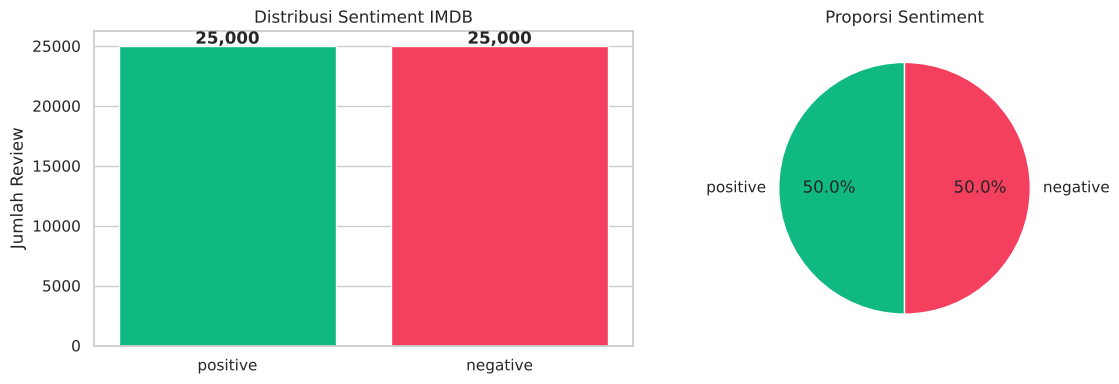

In [3]:
# Distribusi kelas sentiment
sentiment_counts = df['sentiment'].value_counts()
print("Distribusi sentiment:")
print(sentiment_counts)
print(f"\nBalance ratio: {sentiment_counts.min() / sentiment_counts.max():.2%}")

# Visualisasi
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(sentiment_counts.index, sentiment_counts.values,
            color=['#10B981', '#F43F5E'])
axes[0].set_title('Distribusi Sentiment IMDB')
axes[0].set_ylabel('Jumlah Review')
for i, v in enumerate(sentiment_counts.values):
    axes[0].text(i, v + 200, f'{v:,}', ha='center', fontweight='bold')

axes[1].pie(sentiment_counts.values, labels=sentiment_counts.index,
            colors=['#10B981', '#F43F5E'], autopct='%1.1f%%', startangle=90)
axes[1].set_title('Proporsi Sentiment')

plt.tight_layout()
plt.show()


> 💡 **Insight:** Dataset perfectly balanced 50-50 → prior P(positive) = P(negative) = 0.5. Ini penting untuk asumsi Naive Bayes.


## B.2 Panjang Review


Statistik panjang review:


             count    mean     std   min    25%    50%     75%      max
sentiment                                                              
negative   25000.0  1294.0   946.0  32.0  706.0  973.0  1567.0   8969.0
positive   25000.0  1325.0  1031.0  65.0  691.0  968.0  1614.0  13704.0


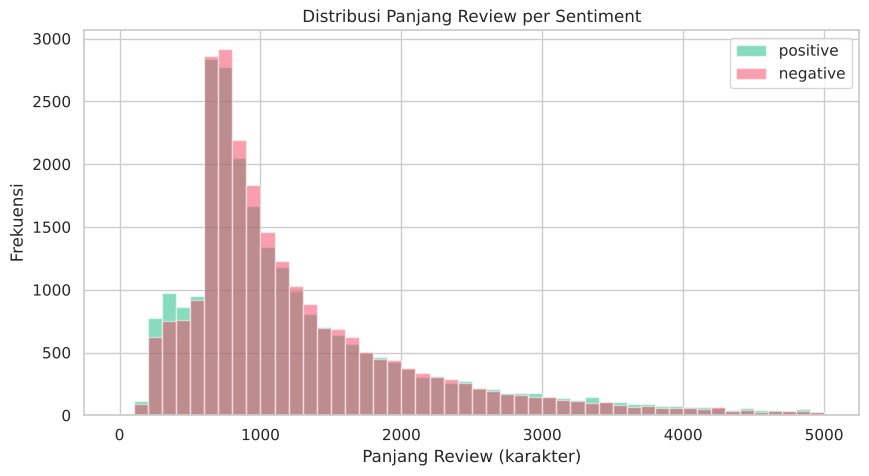

In [4]:
# Panjang review (jumlah karakter)
df['review_length'] = df['review'].str.len()

print("Statistik panjang review:")
print(df.groupby('sentiment')['review_length'].describe().round(0))

# Visualisasi
plt.figure(figsize=(10, 5))
for label, color in zip(['positive', 'negative'], ['#10B981', '#F43F5E']):
    subset = df[df['sentiment'] == label]['review_length']
    plt.hist(subset, bins=50, alpha=0.5, label=label, color=color, range=(0, 5000))

plt.xlabel('Panjang Review (karakter)')
plt.ylabel('Frekuensi')
plt.title('Distribusi Panjang Review per Sentiment')
plt.legend()
plt.show()


## B.3 Sample Review Positif & Negatif


In [5]:
# Tampilkan 1 sample dari masing-masing kelas
print("=" * 60)
print("📗 SAMPLE REVIEW POSITIVE:")
print("=" * 60)
sample_pos = df[df['sentiment'] == 'positive']['review'].iloc[0]
print(sample_pos[:400] + "...")

print("\n" + "=" * 60)
print("📕 SAMPLE REVIEW NEGATIVE:")
print("=" * 60)
sample_neg = df[df['sentiment'] == 'negative']['review'].iloc[0]
print(sample_neg[:400] + "...")


📗 SAMPLE REVIEW POSITIVE:
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to...

📕 SAMPLE REVIEW NEGATIVE:
Basically there's a family where a little boy (Jake) thinks there's a zombie in his closet & his parents are fighting all the time.<br /><br />This movie is slower than a soap opera... and suddenly, Jake decides to become Rambo and kill the zombie.<br /><br />OK, first of all when you're going to make a film you must Decide if its a thriller or a drama! As a drama the movie is watchable. Parents a...


---

# 🎲 C. Probabilitas Bersyarat P(A|B) Empiris

**Tujuan Pembelajaran 1** — Hitung P(A|B) langsung dari data IMDB.

## C.1 Setup: Definisikan Kejadian

Kita ingin menjawab: **"Berapa peluang review POSITIVE jika mengandung kata 'great'?"**

- Event A = review positive
- Event B = review mengandung kata "great"
- Yang dicari: P(A|B) = P(positive | mengandung "great")


In [6]:
# Cari review yang mengandung kata "great" (case-insensitive)
df['has_great'] = df['review'].str.lower().str.contains(r'\bgreat\b', regex=True)

# Hitung tabel kontingensi (crosstab)
contingency = pd.crosstab(df['sentiment'], df['has_great'], margins=True)
print("Tabel Kontingensi: sentiment × mengandung 'great'")
print(contingency)


Tabel Kontingensi: sentiment × mengandung 'great'
has_great  False   True    All
sentiment                     
negative   20902   4098  25000
positive   16522   8478  25000
All        37424  12576  50000


## C.2 Hitung Probabilitas dengan Definisi Klasik

$$P(A|B) = \frac{P(A \cap B)}{P(B)} = \frac{N(A \cap B)}{N(B)}$$


In [7]:
# Total review
N = len(df)

# P(positive) = prior
N_positive = (df['sentiment'] == 'positive').sum()
P_positive = N_positive / N
print(f"P(positive)         = {N_positive}/{N} = {P_positive:.4f}")

# P(has "great") = evidence
N_great = df['has_great'].sum()
P_great = N_great / N
print(f"P(mengandung great) = {N_great}/{N} = {P_great:.4f}")

# P(positive AND has "great") = joint
N_pos_great = ((df['sentiment'] == 'positive') & df['has_great']).sum()
P_pos_and_great = N_pos_great / N
print(f"P(positive ∩ great) = {N_pos_great}/{N} = {P_pos_and_great:.4f}")

# P(positive | has "great") = conditional
P_pos_given_great = P_pos_and_great / P_great
print(f"\n✨ P(positive | great) = {P_pos_and_great:.4f} / {P_great:.4f} = {P_pos_given_great:.4f}")
print(f"   Dibandingkan P(positive) tanpa syarat = {P_positive:.4f}")
print(f"   → Kata 'great' meningkatkan peluang positive sebesar {(P_pos_given_great - P_positive)*100:.1f} percentage points")


P(positive)         = 25000/50000 = 0.5000
P(mengandung great) = 12576/50000 = 0.2515
P(positive ∩ great) = 8478/50000 = 0.1696

✨ P(positive | great) = 0.1696 / 0.2515 = 0.6741
   Dibandingkan P(positive) tanpa syarat = 0.5000
   → Kata 'great' meningkatkan peluang positive sebesar 17.4 percentage points


> 💡 **Interpretasi:** Kata "great" sebagai bukti (evidence) sangat menggeser posterior dari 50% → jauh lebih tinggi. Ini kekuatan Bayes!


## C.3 Latihan Anda: P(negative | "terrible")

Ganti kata "great" dengan "terrible" atau kata lain. Hitung P(negative | mengandung kata itu):


In [8]:
# LATIHAN — ganti kata di bawah dengan kata pilihan Anda
kata_test = "terrible"    # <-- ubah kata ini

df['has_word'] = df['review'].str.lower().str.contains(rf'\b{kata_test}\b', regex=True)

N_word = df['has_word'].sum()
N_neg_word = ((df['sentiment'] == 'negative') & df['has_word']).sum()

if N_word > 0:
    P_word = N_word / N
    P_neg_given_word = N_neg_word / N_word
    P_negative = (df['sentiment'] == 'negative').mean()

    print(f"Kata: '{kata_test}'")
    print(f"Jumlah review mengandung '{kata_test}': {N_word}")
    print(f"P(negative | '{kata_test}') = {P_neg_given_word:.4f}")
    print(f"P(negative) tanpa syarat   = {P_negative:.4f}")
    print(f"Pergeseran probabilitas    = +{(P_neg_given_word - P_negative)*100:.1f} pp")
else:
    print(f"Kata '{kata_test}' tidak ditemukan. Coba kata lain.")


Kata: 'terrible'
Jumlah review mengandung 'terrible': 2701
P(negative | 'terrible') = 0.8582
P(negative) tanpa syarat   = 0.5000
Pergeseran probabilitas    = +35.8 pp


### C.3 Hasil Latihan: Lima Kata Pilihan

Latihan meminta beberapa kata dicoba. Cell berikut menghitung P(negative | kata) dan P(positive | kata) untuk kelima kata, lalu menentukan kata yang paling kuat sebagai penanda sentimen (paling jauh dari prior 0,5).


In [9]:
kata_list = ["awful", "boring", "waste", "excellent", "wonderful"]
baris = []
for k in kata_list:
    ada = df['review'].str.lower().str.contains(rf'\b{k}\b', regex=True)
    n_ada = int(ada.sum())
    p_neg = ((df['sentiment'] == 'negative') & ada).sum() / n_ada
    baris.append({'kata': k, 'jumlah_review': n_ada, 'P(negative|kata)': round(p_neg, 4),
                  'P(positive|kata)': round(1 - p_neg, 4),
                  'geser_dari_0.5_(pp)': round(abs(p_neg - 0.5) * 100, 1)})

hasil_kata = pd.DataFrame(baris).sort_values('geser_dari_0.5_(pp)', ascending=False).reset_index(drop=True)
print(hasil_kata.to_string(index=False))
kuat = hasil_kata.iloc[0]
print(f"\n💡 Penanda terkuat: '{kuat['kata']}' (P(negative|kata) = {kuat['P(negative|kata)']}, geser {kuat['geser_dari_0.5_(pp)']} pp dari prior 0.5)")


     kata  jumlah_review  P(negative|kata)  P(positive|kata)  geser_dari_0.5_(pp)
    waste           2534            0.9309            0.0691                 43.1
    awful           2883            0.9015            0.0985                 40.1
wonderful           2780            0.1878            0.8122                 31.2
excellent           3552            0.1926            0.8074                 30.7
   boring           3051            0.8063            0.1937                 30.6

💡 Penanda terkuat: 'waste' (P(negative|kata) = 0.9309, geser 43.1 pp dari prior 0.5)


> ✏️ **Latihan C**: Coba beberapa kata dan catat P(negative|kata):
> - "awful", "boring", "waste", "excellent", "wonderful"
> - Kata mana yang paling kuat sebagai indikator sentiment?


---

# 📧 D. Teorema Bayes: Spam Filter Manual

**Tujuan Pembelajaran 2** — Terapkan formula Bayes lengkap pada kasus spam filter.

$$P(\text{spam}|\text{kata}) = \frac{P(\text{kata}|\text{spam}) \cdot P(\text{spam})}{P(\text{kata})}$$

## D.1 Skenario

Anggap kita menggunakan review sebagai proxy untuk "email":
- **positive** ↔ email normal
- **negative** ↔ email spam-like (banyak kata negatif)

Kita hitung: **Berapa peluang review NEGATIVE (spam-like) jika mengandung kata "waste"?**


In [10]:
# Kita treat 'negative' sebagai "spam-like" untuk demo
kata = "waste"
df['has_kata'] = df['review'].str.lower().str.contains(rf'\b{kata}\b', regex=True)

# Komponen Bayes
# Prior
P_spam = (df['sentiment'] == 'negative').mean()     # P(spam)
P_ham  = (df['sentiment'] == 'positive').mean()     # P(ham/normal)

# Likelihood
N_spam = (df['sentiment'] == 'negative').sum()
N_ham  = (df['sentiment'] == 'positive').sum()
N_kata_in_spam = ((df['sentiment'] == 'negative') & df['has_kata']).sum()
N_kata_in_ham  = ((df['sentiment'] == 'positive') & df['has_kata']).sum()

P_kata_given_spam = N_kata_in_spam / N_spam    # P(kata | spam)
P_kata_given_ham  = N_kata_in_ham / N_ham      # P(kata | ham)

# Evidence: P(kata) = P(kata|spam)P(spam) + P(kata|ham)P(ham)
P_kata = P_kata_given_spam * P_spam + P_kata_given_ham * P_ham

# Posterior via Bayes
P_spam_given_kata = (P_kata_given_spam * P_spam) / P_kata

print(f"═══════════════════════════════════════════════")
print(f"BAYES CALCULATION: P(negative | '{kata}')")
print(f"═══════════════════════════════════════════════")
print(f"\nPRIOR:")
print(f"  P(negative) = {P_spam:.4f}")
print(f"  P(positive) = {P_ham:.4f}")
print(f"\nLIKELIHOOD:")
print(f"  P('{kata}'|negative) = {P_kata_given_spam:.4f}")
print(f"  P('{kata}'|positive) = {P_kata_given_ham:.4f}")
print(f"\nEVIDENCE:")
print(f"  P('{kata}') = {P_kata:.4f}")
print(f"\n═══════════════════════════════════════════════")
print(f"POSTERIOR:  P(negative | '{kata}') = {P_spam_given_kata:.4f}  ({P_spam_given_kata*100:.1f}%)")
print(f"═══════════════════════════════════════════════")


═══════════════════════════════════════════════
BAYES CALCULATION: P(negative | 'waste')
═══════════════════════════════════════════════

PRIOR:
  P(negative) = 0.5000
  P(positive) = 0.5000

LIKELIHOOD:
  P('waste'|negative) = 0.0944
  P('waste'|positive) = 0.0070

EVIDENCE:
  P('waste') = 0.0507

═══════════════════════════════════════════════
POSTERIOR:  P(negative | 'waste') = 0.9309  (93.1%)
═══════════════════════════════════════════════


> 💡 **Insight**: Prior kita 50/50 (balanced). Setelah tahu kata "waste" muncul, posterior jadi jauh > 50% untuk negative. Bukti kuat mengubah kepercayaan.


---

# 🏥 E. Teorema Bayes: Diagnosis Medis (Paradoks Base Rate)

**Tujuan Pembelajaran 2** — Simulasi klasik yang sering keliru dipahami dokter & masyarakat.

## E.1 Skenario COVID Test

- Test COVID punya **sensitivitas 99%**: P(+ | sakit) = 0.99
- **Spesifisitas 99%**: P(- | sehat) = 0.99, sehingga P(+ | sehat) = 0.01
- **Prevalensi 1%**: P(sakit) = 0.01

**Pertanyaan: Jika seseorang test POSITIF, berapa peluang dia benar-benar sakit?**

Sebelum menghitung, tebak dulu jawabannya... 99%? 95%?


In [11]:
# Setup parameter
P_sakit = 0.01              # prior: prevalensi
P_sehat = 1 - P_sakit       # 0.99

P_pos_given_sakit = 0.99    # sensitivitas
P_pos_given_sehat = 0.01    # false positive rate (1 - spesifisitas)

# Evidence (Total Probability): P(+)
P_positif = P_pos_given_sakit * P_sakit + P_pos_given_sehat * P_sehat

# Posterior via Bayes: P(sakit | +)
P_sakit_given_positif = (P_pos_given_sakit * P_sakit) / P_positif

print(f"═══════════════════════════════════════════════")
print(f"COVID TEST BAYES CALCULATION")
print(f"═══════════════════════════════════════════════")
print(f"\nInput:")
print(f"  P(sakit)          = {P_sakit}  (prior: 1% populasi)")
print(f"  P(+ | sakit)      = {P_pos_given_sakit}  (sensitivitas 99%)")
print(f"  P(+ | sehat)      = {P_pos_given_sehat}  (false positive 1%)")
print(f"\nHitung P(+):")
print(f"  = P(+|sakit)·P(sakit) + P(+|sehat)·P(sehat)")
print(f"  = {P_pos_given_sakit}×{P_sakit} + {P_pos_given_sehat}×{P_sehat}")
print(f"  = {P_pos_given_sakit*P_sakit} + {P_pos_given_sehat*P_sehat}")
print(f"  = {P_positif}")
print(f"\nBayes:")
print(f"  P(sakit | +) = ({P_pos_given_sakit} × {P_sakit}) / {P_positif}")
print(f"═══════════════════════════════════════════════")
print(f"\n✨ P(sakit | +) = {P_sakit_given_positif:.4f}  =  {P_sakit_given_positif*100:.1f}%")
print(f"\n⚠️  Meskipun test 99% akurat, peluang benar sakit hanya {P_sakit_given_positif*100:.0f}%!")
print(f"    Ini karena prior (base rate) sangat rendah.")


═══════════════════════════════════════════════
COVID TEST BAYES CALCULATION
═══════════════════════════════════════════════

Input:
  P(sakit)          = 0.01  (prior: 1% populasi)
  P(+ | sakit)      = 0.99  (sensitivitas 99%)
  P(+ | sehat)      = 0.01  (false positive 1%)

Hitung P(+):
  = P(+|sakit)·P(sakit) + P(+|sehat)·P(sehat)
  = 0.99×0.01 + 0.01×0.99
  = 0.0099 + 0.0099
  = 0.0198

Bayes:
  P(sakit | +) = (0.99 × 0.01) / 0.0198
═══════════════════════════════════════════════

✨ P(sakit | +) = 0.5000  =  50.0%

⚠️  Meskipun test 99% akurat, peluang benar sakit hanya 50%!
    Ini karena prior (base rate) sangat rendah.


## E.2 Visualisasi: Kenapa Bisa Cuma 50%?

Bayangkan populasi 10.000 orang:


Simulasi populasi 10,000 orang:
  100 orang benar-benar sakit
  9,900 orang sehat

Yang test POSITIF:
  ✅ True Positive  (sakit, +): 99
  ❌ False Positive (sehat, +): 99
  Total positif: 198

Dari 198 orang yang positif:
  Hanya 99 yang benar-benar sakit → 50.0%


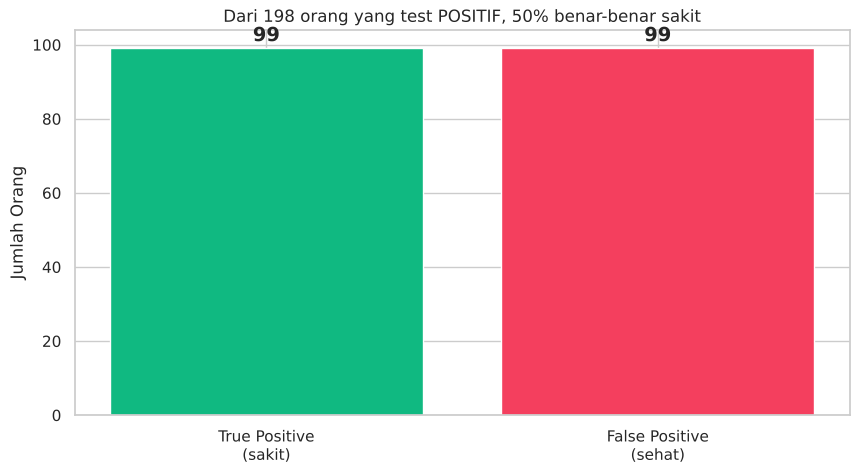

In [12]:
# Simulasi populasi 10.000 orang
N_pop = 10000
N_sakit_pop = int(N_pop * P_sakit)   # 100 orang sakit
N_sehat_pop = N_pop - N_sakit_pop    # 9900 orang sehat

# True positive (sakit dan test +)
TP = int(N_sakit_pop * P_pos_given_sakit)      # ~99 orang
# False positive (sehat tapi test +)
FP = int(N_sehat_pop * P_pos_given_sehat)      # ~99 orang
# Total positif
Total_positif = TP + FP

print(f"Simulasi populasi {N_pop:,} orang:")
print(f"  {N_sakit_pop} orang benar-benar sakit")
print(f"  {N_sehat_pop:,} orang sehat\n")
print(f"Yang test POSITIF:")
print(f"  ✅ True Positive  (sakit, +): {TP}")
print(f"  ❌ False Positive (sehat, +): {FP}")
print(f"  Total positif: {Total_positif}\n")
print(f"Dari {Total_positif} orang yang positif:")
print(f"  Hanya {TP} yang benar-benar sakit → {TP/Total_positif*100:.1f}%")

# Visualisasi
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(['True Positive\n(sakit)', 'False Positive\n(sehat)'],
       [TP, FP], color=['#10B981', '#F43F5E'])
ax.set_ylabel('Jumlah Orang')
ax.set_title(f'Dari {Total_positif} orang yang test POSITIF, {TP/Total_positif*100:.0f}% benar-benar sakit')
for i, v in enumerate([TP, FP]):
    ax.text(i, v + 2, str(v), ha='center', fontweight='bold', fontsize=14)
plt.show()


> 🎯 **Pelajaran:** Base rate (prior) sangat penting! Test yang tampak akurat bisa "berbohong" kalau penyakitnya jarang.


---

# 🤖 F. Naive Bayes Sentiment Analysis — LATIHAN UTAMA

**Tujuan Pembelajaran 3** — Bangun classifier lengkap untuk sentiment IMDB.

## F.1 Preprocessing Text


In [13]:
import re

def clean_text(text):
    """Preprocessing dasar untuk text IMDB."""
    # Lowercase
    text = text.lower()
    # Hapus HTML tags (IMDB reviews punya <br /> dll)
    text = re.sub(r'<[^>]+>', ' ', text)
    # Hapus URL
    text = re.sub(r'http\S+|www\S+', ' ', text)
    # Hapus karakter non-alfabet (kecuali spasi)
    text = re.sub(r'[^a-z\s]', ' ', text)
    # Hapus multiple spaces
    text = re.sub(r'\s+', ' ', text).strip()
    return text

# Contoh cleaning
sample_review = df['review'].iloc[0]
print("SEBELUM cleaning:")
print(sample_review[:200])
print("\nSESUDAH cleaning:")
print(clean_text(sample_review)[:200])

# Aplikasikan ke seluruh dataset
print("\nMembersihkan 50.000 review...")
df['clean_review'] = df['review'].apply(clean_text)
print("Selesai!")


SEBELUM cleaning:
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me abo

SESUDAH cleaning:
one of the other reviewers has mentioned that after watching just oz episode you ll be hooked they are right as this is exactly what happened with me the first thing that struck me about oz was its br

Membersihkan 50.000 review...


Selesai!


## F.2 Encode Label & Train/Test Split


In [14]:
# Encode: positive -> 1, negative -> 0
df['label'] = (df['sentiment'] == 'positive').astype(int)

X = df['clean_review']
y = df['label']

# Stratified split 80/20
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set: {len(X_train):,} review")
print(f"Test set    : {len(X_test):,} review")
print(f"\nDistribusi kelas di training:")
print(y_train.value_counts(normalize=True).round(3))


Training set: 40,000 review
Test set    : 10,000 review

Distribusi kelas di training:
label
1    0.5
0    0.5
Name: proportion, dtype: float64


## F.3 Vectorization dengan TF-IDF

TF-IDF mengubah teks jadi matriks angka. Setiap kolom = kata, setiap baris = review. Nilai = importance skor kata di review itu.


In [15]:
# TfidfVectorizer dengan pengaturan umum
vectorizer = TfidfVectorizer(
    max_features=10000,     # ambil 10.000 kata paling penting
    ngram_range=(1, 2),     # unigram + bigram (kata tunggal & pasangan)
    min_df=5,               # kata harus muncul di min 5 review
    max_df=0.8,             # dan max di 80% review (buang kata terlalu umum)
    stop_words='english',   # buang stop words (the, is, and, ...)
)

# Fit dari training, transform train + test
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

print(f"Matriks TF-IDF training: {X_train_vec.shape}")
print(f"Matriks TF-IDF test    : {X_test_vec.shape}")
print(f"\nContoh 20 kata dari vocabulary:")
print(vectorizer.get_feature_names_out()[500:520])


Matriks TF-IDF training: (40000, 10000)
Matriks TF-IDF test    : (10000, 10000)

Contoh 20 kata dari vocabulary:
['attempting' 'attempts' 'attenborough' 'attend' 'attended' 'attending'
 'attention' 'attic' 'attitude' 'attitudes' 'attorney' 'attract'
 'attracted' 'attraction' 'attractive' 'audience' 'audiences' 'audio'
 'audition' 'audrey']


## F.4 Training MultinomialNB


In [16]:
# Latih model - training instan!
print("Training MultinomialNB...")
model = MultinomialNB()
model.fit(X_train_vec, y_train)
print("✅ Model selesai dilatih!")

# Predict
y_pred = model.predict(X_test_vec)

# Evaluasi
acc = accuracy_score(y_test, y_pred)
print(f"\n🎯 Akurasi pada test set: {acc:.4f}  ({acc*100:.2f}%)")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['negative', 'positive']))


Training MultinomialNB...
✅ Model selesai dilatih!

🎯 Akurasi pada test set: 0.8641  (86.41%)

Classification Report:
              precision    recall  f1-score   support

    negative       0.88      0.85      0.86      5000
    positive       0.85      0.88      0.87      5000

    accuracy                           0.86     10000
   macro avg       0.86      0.86      0.86     10000
weighted avg       0.86      0.86      0.86     10000



## F.5 Confusion Matrix


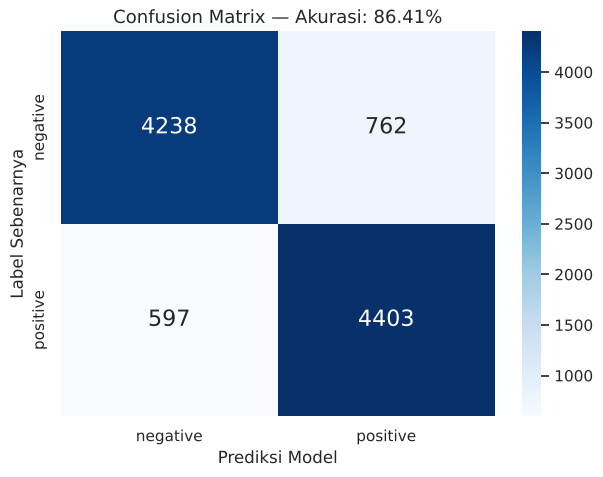


Breakdown:
  True Negative  (benar negative): 4238
  False Positive (salah positive): 762
  False Negative (salah negative): 597
  True Positive  (benar positive): 4403


In [17]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['negative', 'positive'],
            yticklabels=['negative', 'positive'],
            annot_kws={'size': 16})
plt.xlabel('Prediksi Model', fontsize=12)
plt.ylabel('Label Sebenarnya', fontsize=12)
plt.title(f'Confusion Matrix — Akurasi: {acc*100:.2f}%', fontsize=13)
plt.show()

# Breakdown
TN, FP, FN, TP = cm.ravel()
print(f"\nBreakdown:")
print(f"  True Negative  (benar negative): {TN}")
print(f"  False Positive (salah positive): {FP}")
print(f"  False Negative (salah negative): {FN}")
print(f"  True Positive  (benar positive): {TP}")


## F.6 Kata Paling Indikatif untuk Setiap Kelas

Model MultinomialNB menyimpan log-probability untuk tiap kata di tiap kelas. Kita cari kata dengan **rasio log-prob** terbesar.


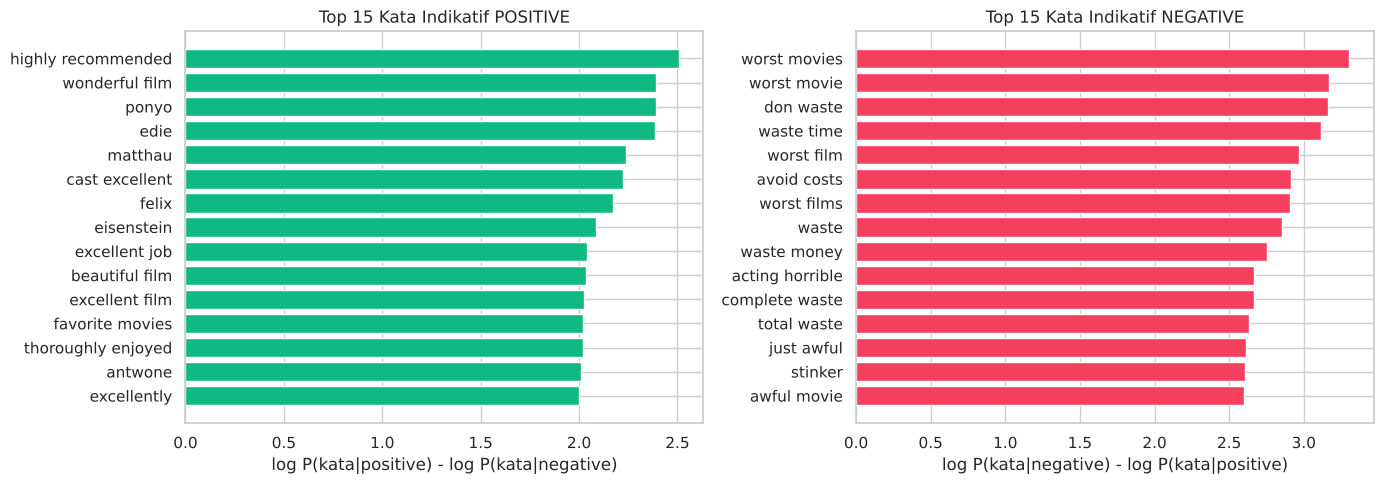

In [18]:
# feature_log_prob_ shape: (n_classes, n_features)
# [0] = negative, [1] = positive
log_prob_neg = model.feature_log_prob_[0]
log_prob_pos = model.feature_log_prob_[1]

# Rasio: kata mana yang jauh lebih probable di positive vs negative
diff = log_prob_pos - log_prob_neg

feature_names = np.array(vectorizer.get_feature_names_out())

# Top 15 kata untuk positive (diff paling positif)
top_positive_idx = diff.argsort()[-15:][::-1]
top_positive_words = feature_names[top_positive_idx]

# Top 15 kata untuk negative (diff paling negatif)
top_negative_idx = diff.argsort()[:15]
top_negative_words = feature_names[top_negative_idx]

# Visualize
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].barh(range(15), diff[top_positive_idx][::-1], color='#10B981')
axes[0].set_yticks(range(15))
axes[0].set_yticklabels(top_positive_words[::-1])
axes[0].set_title('Top 15 Kata Indikatif POSITIVE')
axes[0].set_xlabel('log P(kata|positive) - log P(kata|negative)')

axes[1].barh(range(15), -diff[top_negative_idx][::-1], color='#F43F5E')
axes[1].set_yticks(range(15))
axes[1].set_yticklabels(top_negative_words[::-1])
axes[1].set_title('Top 15 Kata Indikatif NEGATIVE')
axes[1].set_xlabel('log P(kata|negative) - log P(kata|positive)')

plt.tight_layout()
plt.show()


## F.7 Predict Review yang Anda Tulis Sendiri!


In [19]:
def predict_sentiment(review_text):
    """Prediksi sentiment review baru."""
    cleaned = clean_text(review_text)
    vec = vectorizer.transform([cleaned])
    prob = model.predict_proba(vec)[0]
    pred = model.predict(vec)[0]
    label = 'POSITIVE 🟢' if pred == 1 else 'NEGATIVE 🔴'

    print(f"Review: \"{review_text[:150]}...\"" if len(review_text) > 150 else f'Review: "{review_text}"')
    print(f"\nPrediksi     : {label}")
    print(f"P(negative)  : {prob[0]:.4f}  ({prob[0]*100:.1f}%)")
    print(f"P(positive)  : {prob[1]:.4f}  ({prob[1]*100:.1f}%)")
    print("-" * 60)

# Coba 3 review
predict_sentiment("This movie was absolutely fantastic! The acting was superb and the story was so engaging.")

predict_sentiment("I fell asleep halfway through. The plot was boring and the acting was terrible.")

predict_sentiment("The film had some good moments but overall was quite average.")


Review: "This movie was absolutely fantastic! The acting was superb and the story was so engaging."

Prediksi     : POSITIVE 🟢
P(negative)  : 0.1384  (13.8%)
P(positive)  : 0.8616  (86.2%)
------------------------------------------------------------
Review: "I fell asleep halfway through. The plot was boring and the acting was terrible."

Prediksi     : NEGATIVE 🔴
P(negative)  : 0.9822  (98.2%)
P(positive)  : 0.0178  (1.8%)
------------------------------------------------------------
Review: "The film had some good moments but overall was quite average."

Prediksi     : POSITIVE 🟢
P(negative)  : 0.4536  (45.4%)
P(positive)  : 0.5464  (54.6%)
------------------------------------------------------------


> ✏️ **Latihan F**: Coba tulis review Anda sendiri (bahasa Inggris) dan test:
> - Review super positif
> - Review sangat negatif
> - Review ambigu ("mixed feelings") — bagaimana keyakinan model?


In [20]:
# LATIHAN F.7 — Review buatan sendiri (3 review + 1 review ambigu)
review_positif = "An absolutely brilliant film. The performances were wonderful, the story was moving, and I would highly recommend it to everyone."
review_negatif = "A complete waste of time. The plot was boring, the acting was awful, and it is the worst movie I have seen this year."
review_ambigu  = "The visuals were beautiful but the story was weak and the ending felt rushed. Some good moments, some bad ones."
review_anda    = "I expected more from this movie. It was not terrible, but it was not great either."

for r in [review_positif, review_negatif, review_ambigu, review_anda]:
    predict_sentiment(r)


Review: "An absolutely brilliant film. The performances were wonderful, the story was moving, and I would highly recommend it to everyone."

Prediksi     : POSITIVE 🟢
P(negative)  : 0.0535  (5.3%)
P(positive)  : 0.9465  (94.7%)
------------------------------------------------------------
Review: "A complete waste of time. The plot was boring, the acting was awful, and it is the worst movie I have seen this year."

Prediksi     : NEGATIVE 🔴
P(negative)  : 0.9968  (99.7%)
P(positive)  : 0.0032  (0.3%)
------------------------------------------------------------
Review: "The visuals were beautiful but the story was weak and the ending felt rushed. Some good moments, some bad ones."

Prediksi     : NEGATIVE 🔴
P(negative)  : 0.5451  (54.5%)
P(positive)  : 0.4549  (45.5%)
------------------------------------------------------------
Review: "I expected more from this movie. It was not terrible, but it was not great either."

Prediksi     : NEGATIVE 🔴
P(negative)  : 0.9228  (92.3%)
P(positive)

---

# 📊 G. Posterior Update: Visualisasi Bayesian Learning

**Tujuan Pembelajaran 4** — Lihat bagaimana kepercayaan (belief) berubah saat data masuk.

## G.1 Contoh: Estimasi Proporsi Review Positif

Anggap kita adalah analis baru yang belum tahu apa-apa tentang IMDB. Kita mulai dengan **prior uniform** — bisa jadi mayoritas positive, atau mayoritas negative, kita tidak tahu.

Kemudian, kita mulai membaca review satu per satu. Setelah tiap review, kita **update posterior** kepercayaan kita.

Kita gunakan distribusi Beta sebagai prior:
- Beta(1, 1) = uniform prior (tidak tahu apa-apa)
- Setelah lihat k positive dari n review: Beta(1+k, 1+(n-k))


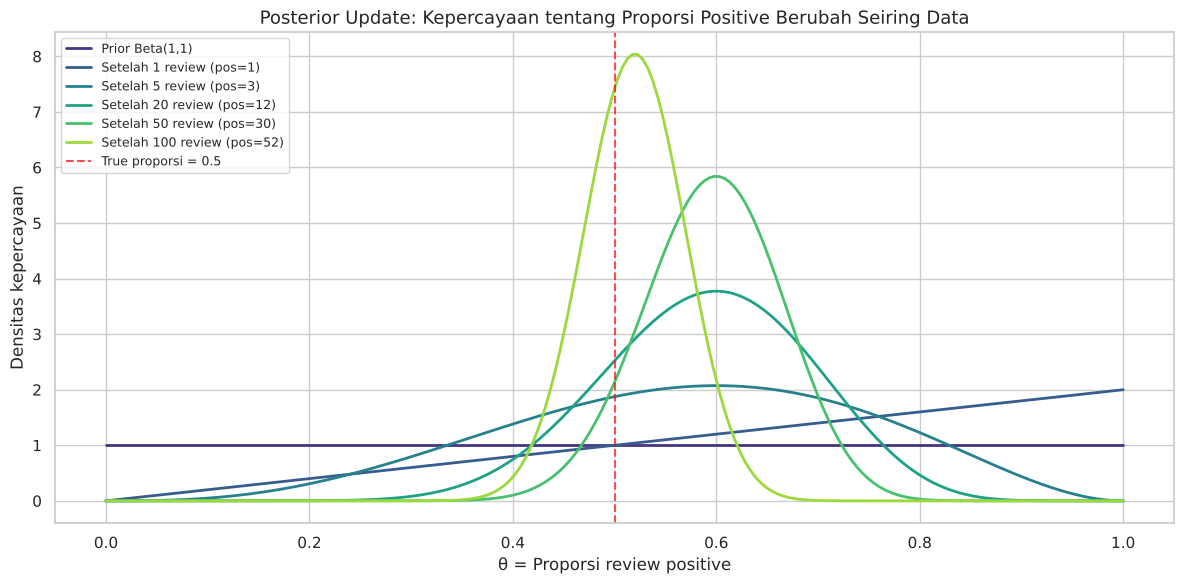

In [21]:
# Ambil sampel 100 review acak
sample_reviews = df.sample(n=100, random_state=42)['sentiment'].values

# Simulasi posterior update setelah lihat 1, 5, 20, 50, 100 review
milestones = [0, 1, 5, 20, 50, 100]
theta = np.linspace(0, 1, 200)

plt.figure(figsize=(12, 6))
colors = plt.cm.viridis(np.linspace(0.15, 0.85, len(milestones)))

for i, n_seen in enumerate(milestones):
    if n_seen == 0:
        # Prior Beta(1, 1) - uniform
        alpha, beta_param = 1, 1
        label = f'Prior Beta(1,1)'
    else:
        k = (sample_reviews[:n_seen] == 'positive').sum()
        # Posterior Beta(1+k, 1+(n-k))
        alpha = 1 + k
        beta_param = 1 + (n_seen - k)
        label = f'Setelah {n_seen} review (pos={k})'

    pdf = beta.pdf(theta, alpha, beta_param)
    plt.plot(theta, pdf, color=colors[i], linewidth=2, label=label)

plt.axvline(0.5, color='red', linestyle='--', alpha=0.7, label='True proporsi = 0.5')
plt.xlabel('θ = Proporsi review positive', fontsize=12)
plt.ylabel('Densitas kepercayaan', fontsize=12)
plt.title('Posterior Update: Kepercayaan tentang Proporsi Positive Berubah Seiring Data', fontsize=13)
plt.legend(loc='upper left', fontsize=9)
plt.tight_layout()
plt.show()


> 🔍 **Interpretasi:**
> - **Kurva prior (kuning)** flat — kita tidak tahu apa-apa, semua nilai 0-1 sama mungkin.
> - Semakin banyak review yang dilihat, kurva **makin tajam dan terpusat** di sekitar nilai sebenarnya (~0.5).
> - Ini esensi Bayesian learning: **kepercayaan makin pasti seiring bukti bertambah**.


## G.2 Koneksi ke LLM Confidence

Konsep yang sama berlaku di LLM (ChatGPT, Claude, Gemini):

- **Prior**: distribusi bahasa dari korpus training raksasa
- **Evidence (Likelihood)**: prompt Anda yang menyempitkan konteks
- **Posterior**: P(token berikutnya | prompt) — inilah yang di-sample

Semakin spesifik prompt → posterior makin tajam → jawaban makin deterministik.  
Prompt vague → posterior menyebar → LLM cenderung bervariasi/kreatif.

Parameter **temperature** di LLM mengontrol seberapa "tajam" atau "menyebar" posterior itu di-sample.


---

# 📝 H. Refleksi & Submit

## H.1 Pertanyaan Refleksi

Jawab 5 pertanyaan berikut di cell markdown di bawah:

1. **P(A|B)**: Jelaskan dengan kata-kata sendiri kenapa P(positive | "great") ≠ P(positive).

2. **Bayes**: Dalam kasus diagnosis COVID (99% akurat), kenapa peluang benar sakit hanya 50%? Apa yang membuat "paradoks" ini muncul?

3. **Naive Bayes**: Apa arti "naif" di Naive Bayes? Berikan 1 contoh di IMDB dimana asumsi ini mungkin dilanggar.

4. **Feature Importance**: Dari top 15 kata negative yang keluar, apakah ada yang mengejutkan? Kenapa "bad", "worst", "waste" menjadi indikator kuat?

5. **Posterior Update**: Bagaimana konsep prior → likelihood → posterior muncul di kehidupan sehari-hari (di luar konteks ML)?

### ✏️ Jawaban Anda:

**1. P(A|B):** P(positive | "great") = 0,6741, sedangkan P(positive) = 0,5. Keduanya berbeda karena kata "great" lebih sering muncul di review positif (8.478 review) daripada di review negatif (4.098 review). Syarat "mengandung great" mempersempit ruang sampel menjadi 12.576 review, dan di ruang yang lebih kecil itu proporsi positifnya lebih tinggi. Jika kata itu tidak berpengaruh, kedua nilai akan sama (kejadian independen).

**2. Bayes (COVID):** Prevalensi hanya 1%, jadi dari 10.000 orang hanya 100 yang sakit dan 9.900 sehat. Tes menangkap 99 dari 100 orang sakit (true positive), tetapi 1% dari 9.900 orang sehat, yaitu 99 orang, ikut positif (false positive). Dari 198 orang yang positif, hanya 99 yang benar-benar sakit, jadi 50%. "Paradoks" muncul karena kita lupa memperhitungkan prior (base rate) yang sangat kecil: akurasi tes tinggi tidak otomatis berarti hasil positif pasti benar.

**3. Naive Bayes:** "Naif" berarti model menganggap semua fitur (kata) saling independen jika kelasnya diketahui, sehingga peluangnya tinggal dikalikan. Di IMDB asumsi ini dilanggar, misalnya pada "not good" (arti "good" dibalik oleh "not") atau pada frasa "waste time" dan "complete waste" yang kata-katanya berkaitan. Buktinya ada di Latihan F.7: review "It was not terrible, but it was not great either" diprediksi NEGATIVE dengan peluang 92,3%, karena model menghitung "terrible" dan "great" secara terpisah dan mengabaikan kata "not" di depannya. Meski begitu modelnya tetap mencapai akurasi sekitar 86%.

**4. Feature Importance:** Kata penanda negatif teratas pada grafik adalah frasa seperti worst movie, waste time, avoid costs, awful movie, dan acting horrible. Kata "waste" kuat karena muncul di 9,44% review negatif tetapi hanya 0,70% review positif (rasio sekitar 13 kali), dan P(negative | waste) = 0,9309. Hal yang mengejutkan: di daftar penanda positif ada nama orang (ponyo, edie, matthau, felix) yang hanya kebetulan sering muncul di review positif pada data latih. Itu tanda model bisa menghafal kebetulan data, bukan makna.

**5. Posterior Update:** Contoh sehari-hari: pagi hari saya menduga hujan jarang turun (prior), lalu melihat awan gelap dan angin kencang (bukti). Dugaan saya naik menjadi "kemungkinan besar hujan" (posterior), jadi saya membawa payung. Jika sore harinya langit cerah lagi, dugaan itu turun. Posterior hari ini menjadi prior untuk keputusan berikutnya.


## H.2 Checklist Submit

Sebelum submit, pastikan:

- [ ] Semua cell code berhasil dijalankan tanpa error
- [ ] Latihan C.3 sudah diisi (kata pilihan sendiri untuk P(A|B))
- [ ] Latihan F.7 sudah diisi (minimal 3 review buatan sendiri)
- [ ] Akurasi model MultinomialNB ≥ 85%
- [ ] 5 pertanyaan refleksi sudah dijawab
- [ ] Notebook di-rename: `M3-Praktikum-Bayes-IMDB-NamaAnda.ipynb`
- [ ] Notebook di-download dari Colab (File → Download → .ipynb)
- [ ] Notebook di-upload ke GitHub repository Anda
- [ ] Link GitHub dikumpulkan via LMS Uniska

## H.3 Push ke GitHub

**Melalui Web:**
1. Buka repository `statistika-probabilitas-uniska` di GitHub Anda.
2. Klik folder `notebooks/`, lalu **Add file → Upload files**.
3. Drag & drop file `M3-Praktikum-Bayes-IMDB-NamaAnda.ipynb`.
4. Commit message: `"Add Modul 3 praktikum: Bayes & Naive Bayes IMDB"`.
5. Klik **Commit changes**.

---

## 🎓 Selamat! Anda Berhasil...

✅ Menghitung P(A|B) empiris dari 50.000 review nyata  
✅ Menerapkan Teorema Bayes untuk spam filter & diagnosis medis  
✅ Membangun sentiment analyzer dengan akurasi > 85%  
✅ Memvisualisasikan posterior update sebagai proses belajar Bayesian  

## 📚 Bacaan Lanjutan

- **Bruce, P.** (2020). *Practical Statistics for Data Scientists*, Chapter 6 (Statistical Machine Learning).
- **VanderPlas, J.** (2023). *Python Data Science Handbook*, Section 5.05 (In-Depth: Naive Bayes).
- **Kaggle Learn** — [Intermediate Machine Learning](https://www.kaggle.com/learn/intermediate-machine-learning).

## 🔮 Persiapan Modul 4

Modul 4 membahas **variabel acak**:
- PMF, PDF, CDF
- Ekspektasi & variansi
- Softmax & LLM temperature sampling
- Stochastic Gradient Descent

**Tugas Mandiri sebelum M4:**
1. Selesaikan Kaggle Learn "Intro to Machine Learning" (5 jam).
2. Baca Bruce Ch. 6 (Statistical Machine Learning).
3. **BELAJAR untuk QUIZ 1** minggu depan (Bayes + probabilitas dasar).

---

*Notebook by: Prodi Teknik Informatika · Uniska MAB Banjarmasin · Edisi 2026*
